In [2]:
import dotenv 

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [4]:

os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')

In [ ]:

os.environ['TAVILY_API_KEY']=os.getenv('TAVILY_API_KEY')

os.environ['LANGCHAIN_API_KEY']=os.getenv('LANGCHAIN_API_KEY')




In [6]:
from langchain.chat_models import init_chat_model
llm= init_chat_model(model="openai/gpt-oss-120b",model_provider='groq')

In [7]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

C:\Users\hpvic\AppData\Local\Temp\ipykernel_23308\1871147362.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun


In [8]:
api_wrapper_arxiv= ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)

print(arxiv.name)

arxiv


In [9]:
import arxiv
from langchain_community.utilities import ArxivAPIWrapper
from langchain_community.tools import ArxivQueryRun

# Fix for AttributeError: 'Search' object has no attribute 'results'
arxiv.Search.results = lambda self, *args, **kwargs: arxiv.Client().results(self, *args, **kwargs)

# Tool initialize karein
arxiv_tool = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())

# Search run karein
response = arxiv_tool.invoke("Attention is all you need")
print(response)

Published: 2021-05-06
Title: Do You Even Need Attention? A Stack of Feed-Forward Layers Does Surprisingly Well on ImageNet
Authors: Luke Melas-Kyriazi
Summary: The strong performance of vision transformers on image classification and other vision tasks is often attributed to the design of their multi-head attention layers. However, the extent to which attention is responsible for this strong performance remains unclear. In this short report, we ask: is the attention layer even necessary? Specifically, we replace the attention layer in a vision transformer with a feed-forward layer applied over the patch dimension. The resulting architecture is simply a series of feed-forward layers applied over the patch and feature dimensions in an alternating fashion. In experiments on ImageNet, this architecture performs surprisingly well: a ViT/DeiT-base-sized model obtains 74.9\% top-1 accuracy, compared to 77.9\% and 79.9\% for ViT and DeiT respectively. These results indicate that aspects of vis

In [10]:
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper
from langchain_community.tools import WikipediaQueryRun, ArxivQueryRun

# 1. Wikipedia Tool
api_wrapper_wiki = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=500)
wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)


# Check names
print(wiki.name)   # Output: wikipedia


wikipedia


In [11]:

from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.tools import WikipediaQueryRun

api_wrapper_wiki = WikipediaAPIWrapper(
    top_k_results=2,
    doc_content_chars_max=500)

wiki = WikipediaQueryRun(
    api_wrapper=api_wrapper_wiki)

result = wiki.invoke("What is Deep Learning?")

print(result)

Page: Deep reinforcement learning
Summary: Deep reinforcement learning (deep RL) is a subfield of machine learning that combines reinforcement learning (RL) and deep learning. RL considers the problem of a computational agent learning to make decisions by trial and error. Deep RL incorporates deep learning into the solution, allowing agents to make decisions from unstructured input data without manual engineering of the state space. Deep RL algorithms are able to take in very large inputs (e.g. 


In [12]:
# tavily tool

In [13]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily= TavilySearchResults()

C:\Users\hpvic\AppData\Local\Temp\ipykernel_23308\3527437817.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily= TavilySearchResults()


In [14]:
tavily.invoke('provide recent ai news nov 2026')

[{'title': 'Latest AI News | 5th Nov 2026 (EST) | Apple Cuts AI Budget, Microsoft Walks Away and AI PACs Spend B',
  'url': 'https://www.youtube.com/watch?v=OyLJLtug_lo',
  'content': "Today's top AI news: Apple reportedly slashes internal AI spending, Microsoft walks away from a $170 billion AI deal, AI PACs spent millions on the midterms, Nothing teases an AI-first device, OpenAI reveals a plan for responsible AI infrastructure, and more. We break down what each story means for you — no jargon, just the facts. Plus, we cover the AI market rotation and Arm's stock drop. Stay informed on the AI boom and how it affects your job, your phone, and your wallet. Subscribe for daily AI news in plain English!\n\n━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━\n🔔 SUBSCRIBE for daily AI & tech news — new video every day!\n👍 LIKE if you found this helpful!\n💬 COMMENT your thoughts or questions below!\n🔔 Hit the notification bell so you never miss an update! [...] [0:47] What this means for you, soon the A

In [15]:
# combine all tool in list

In [16]:
tool=[arxiv_tool,wiki,tavily]

In [17]:
from langchain.messages import AIMessage,HumanMessage,SystemMessage, AnyMessage

In [18]:
llm_with_tool=llm.bind_tools(tool)

llm_with_tool.invoke([HumanMessage(content='what is llm model')])

AIMessage(content='**Large Language Model (LLM)**  \n\nA **large language model (LLM)** is a type of artificial‑intelligence system that learns to generate, understand, and manipulate natural‑language text (or code) by training on massive corpora of written material.  \n\n---\n\n## Core Characteristics\n\n| Aspect | What it Means |\n|--------|---------------|\n| **Scale** | “Large” refers to both the amount of training data (often billions of words/tokens) and the size of the neural network (hundreds of millions to trillions of parameters). |\n| **Architecture** | Most modern LLMs use the **Transformer** architecture (Vaswani et\u202fal., 2017). The key component is the self‑attention mechanism, which lets the model weigh the relevance of every token to every other token in a sequence. |\n| **Training Objective** | Typically **next‑token prediction** (autoregressive) or **masked token prediction** (encoder‑only). The model learns to assign high probability to the correct next word give

In [19]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages

In [20]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain.messages import AnyMessage
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [27]:
from langgraph.graph import StateGraph,END,START

from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


In [28]:
def multiply(a:int,b:int)->int:
    """Multiply a and b 
    Args:
        a first int
        b second int
    """
    return a*b
def add(a:int,b:int)->int:
    """Addition a and b 
    Args:
        a first int
        b second int
    """
    return a+b
def divide(a:int,b:int)->int:
    """Divide a and b 
    Args:
        a first int
        b second int
    """
    return a/b

In [30]:
tool=[arxiv_tool,wiki,tavily,add,multiply,divide]

In [29]:
#Node 
def tool_call_llm(state:State):
    return {'messages':[llm_with_tool.invoke(state['messages'])]}

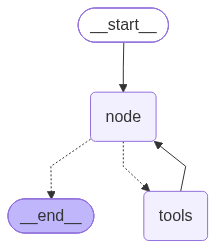

In [34]:
graph = StateGraph(State)


graph.add_node('node', tool_call_llm)
graph.add_node('tools', ToolNode(tool))


graph.add_edge(START, 'node')

graph.add_conditional_edges('node', tools_condition)


graph.add_edge('tools', 'node')


graph.compile()

In [35]:
graph.compile().invoke({'messages':HumanMessage(content='what is machine learning')})

{'messages': [HumanMessage(content='what is machine learning', additional_kwargs={}, response_metadata={}, id='69c5caba-2354-41b4-8ea5-f2478330d1b2'),
  AIMessage(content='**Machine learning (ML)** is a sub‑field of artificial intelligence that focuses on developing algorithms and statistical models that enable computers to *learn* from data—i.e., to improve their performance on a task without being explicitly programmed for every possible scenario.\n\n---\n\n## Core Idea\n- **Learning from examples**: Instead of writing explicit rules, we feed the system a collection of examples (training data) and let it infer patterns.\n- **Generalization**: The goal is to perform well on new, unseen data (test data) by extracting underlying regularities rather than memorizing the training set.\n\n---\n\n## Basic Workflow\n\n| Step | Description |\n|------|-------------|\n| **1. Data collection** | Gather raw observations (images, text, sensor readings, etc.). |\n| **2. Pre‑processing** | Clean, nor

In [39]:
for m in graph.compile().invoke({'messages':HumanMessage(content='who is narendra modi what is  2 plus 2')})['messages']:
    m.pretty_print()

================================ Human Message =================================

who is narendra modi what is  2 plus 2
================================== Ai Message ==================================

**Narendra Modi**  
Narendra Modi is an Indian politician who has served as the 14th Prime Minister of India since May 2014. He is a member of the Bharatiya Janata Party (BJP) and previously served as the Chief Minister of the state of Gujarat from 2001 to 2014. Under his leadership, the BJP has pursued policies focused on economic reforms, infrastructure development, digital initiatives (e.g., “Digital India”), and a strong emphasis on nationalism and cultural identity. Modi is a highly influential figure both domestically and internationally, often shaping India’s foreign policy and economic agenda.

**2 plus 2**  
\(2 + 2 = 4\).


In [40]:
# memory saver

In [41]:
from langgraph.checkpoint.memory  import MemorySaver

memory= MemorySaver()

In [42]:
graph_memory= graph.compile(checkpointer=memory)

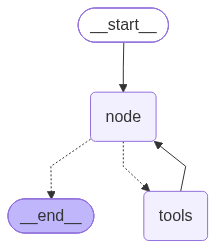

In [43]:
graph_memory

In [44]:
config={'configurable':{'thread_id':"1"}}

In [45]:
for m in graph.compile(checkpointer=memory).invoke({'messages':HumanMessage(content='who is narendra modi what is  2 plus 2')},config=config)['messages']:
    m.pretty_print()

================================ Human Message =================================

who is narendra modi what is  2 plus 2
================================== Ai Message ==================================

**Narendra Modi**

Narendra Modi is an Indian politician who has been serving as the **Prime Minister of India** since May 2014. He is a member of the Bharatiya Janata Party (BJP) and the Rashtriya Swayamsevak Sangh (RSS) ideological parent organization. Before becoming prime minister, Modi was the Chief Minister of the western Indian state of Gujarat from 2001 to 2014. Under his leadership, the BJP has pursued policies emphasizing economic reforms, infrastructure development, digitalization (e.g., “Digital India”), and a strong nationalist agenda. He has been re‑elected as prime minister in the 2019 general election and continues to be a highly influential and sometimes controversial figure both domestically and internationally.

**2 + 2**

\(2 + 2 = 4\).


In [46]:
for m in graph.compile(checkpointer=memory).invoke({'messages':HumanMessage(content='what i asked last time')},config=config)['messages']:
    m.pretty_print()

================================ Human Message =================================

who is narendra modi what is  2 plus 2
================================== Ai Message ==================================

**Narendra Modi**

Narendra Modi is an Indian politician who has been serving as the **Prime Minister of India** since May 2014. He is a member of the Bharatiya Janata Party (BJP) and the Rashtriya Swayamsevak Sangh (RSS) ideological parent organization. Before becoming prime minister, Modi was the Chief Minister of the western Indian state of Gujarat from 2001 to 2014. Under his leadership, the BJP has pursued policies emphasizing economic reforms, infrastructure development, digitalization (e.g., “Digital India”), and a strong nationalist agenda. He has been re‑elected as prime minister in the 2019 general election and continues to be a highly influential and sometimes controversial figure both domestically and internationally.

**2 + 2**

\(2 + 2 = 4\).
==============================